In [2]:
import solarpy as sp
import pandas as pd
import numpy as np
from numpy import pi, exp, sqrt, sin, cos, tan, arccos
from datetime import datetime, timedelta

from scipy.constants import h, c, k

import matplotlib
from matplotlib import rc
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from matplotlib.patches import Circle, Rectangle
from mpl_toolkits.axes_grid.inset_locator import (inset_axes, InsetPosition, mark_inset)

<ipython-input-2-69e7b5d831f8>:14: MatplotlibDeprecationWarning: 
The mpl_toolkits.axes_grid module was deprecated in Matplotlib 2.1 and will be removed two minor releases later. Use mpl_toolkits.axes_grid1 and mpl_toolkits.axisartist, which provide the same functionality instead.
  from mpl_toolkits.axes_grid.inset_locator import (inset_axes, InsetPosition, mark_inset)


In [3]:
### load datasets

# sun radiation spectral quantities from "Preetham et al. - A Practical Analytic Model for Daylight (Appendix A.6, Table 2)"
data0 = np.loadtxt('/Users/canartun/OneDrive/RESEARCH/SUNDOWNING SYNDROME/Datasets/S0.txt')
data1 = np.loadtxt('/Users/canartun/OneDrive/RESEARCH/SUNDOWNING SYNDROME/Datasets/S1.txt')
data2 = np.loadtxt('/Users/canartun/OneDrive/RESEARCH/SUNDOWNING SYNDROME/Datasets/S2.txt')

S0  = data0[:,1] # scattering 0. sun radiation mean spectral radiant power (wavelength (nm, ?))
S1  = data1[:,1] # scattering 1
S2  = data2[:,1] # scattering 2

# photopic limunosity from www.cvrl.org, "CIE Photopic V(λ) modified by Judd (1951) and Vos (1978) [also known as CIE VM(λ)]", (wavelength (nm), luminous effiency (energy)) (380-780 nm in 5 nm steps)
photopic = pd.read_csv('/Users/canartun/OneDrive/RESEARCH/SUNDOWNING SYNDROME/Datasets/vljve.csv',skiprows=0,na_values = ['0'])
photopic_array = photopic.to_numpy()
photopic_V = photopic_array[:,1]

# scotopic limunosity from www.cvrl.org, "CIE (1951) Scotopic V'(λ)", (wavelength (nm), luminous effiency (energy)) (380-780 nm in 5 nm steps)
scotopic = pd.read_csv('/Users/canartun/OneDrive/RESEARCH/SUNDOWNING SYNDROME/Datasets/scvle.csv',skiprows=0,na_values = ['0'])
scotopic_array = scotopic.to_numpy()
scotopic_V = scotopic_array[:,1]

# the CIE colour matching function for 380 - 780 nm in 10 nm intervals
cmf = np.loadtxt('/Users/canartun/OneDrive/RESEARCH/SUNDOWNING SYNDROME/Datasets/cie-cmf.txt', usecols=(1,2,3))

### City - Latitude Dictionaries

In [4]:
### matching cities with latitudes

latitude_city = {55.7: "Moscow",
                 52  : "Berlin",
                 51.5: "London",
                 41  : "Istanbul",
                 32.8: "Tripoli",
                 30  : "Cairo",
                 25  : "Sicily",
                -33.9: "Cape Town"}

city_latitude = {"Moscow"   : 55.7,
                 "Berlin"   : 52,
                 "London"   : 51.5,
                 "Istanbul" : 41,
                 "Tripoli"  : 32.8,
                 "Cairo"    : 30,
                 "Sicily"   : 25,
                 "Cape Town":-33.9}

### Color System Functions

In [5]:
### define these necessary functions

def xyz_from_xy(x, y):
    
    return np.array((x, y, 1-x-y))

class ColourSystem:
    
    # the CIE colour matching function for 380 - 780 nm in 10 nm intervals
    #cmf = np.loadtxt('/Users/canartun/OneDrive/RESEARCH/SUNDOWNING SYNDROME/Datasets/cie-cmf.txt', usecols=(1,2,3))
        
    def __init__(self, red, green, blue, white):
        
        # chromaticities
        self.red, self.green, self.blue = red, green, blue
        self.white = white
        
        # the chromaticity matrix (rgb -> xyz) and its inverse
        self.M = np.vstack((self.red, self.green, self.blue)).T 
        self.MI = np.linalg.inv(self.M)
        
        # white scaling array
        self.wscale = self.MI.dot(self.white)
        
        # xyz -> rgb transformation matrix
        self.T = self.MI / self.wscale[:, np.newaxis]
    
    def xyz_to_rgb(self, xyz, out_fmt=None):
        
        rgb = self.T.dot(xyz)
        
        if np.any(rgb < 0):
            # we're not in the RGB gamut: approximate by desaturating
            w = - np.min(rgb)
            rgb += w
            
        if not np.all(rgb == 0):
            # normalize the rgb vector
            rgb /= np.max(rgb)
        
        if out_fmt == 'html':
            return self.rgb_to_hex(rgb)
        
        return rgb
        
    def rgb_to_hex(self, rgb):
        
        hex_rgb = (255*rgb).astype(int)
        
        return '#{:02x}{:02x}{:02x}'.format(*hex_rgb)

    def spec_to_xyz(self, spec):
        
        XYZ = np.sum(spec[:, np.newaxis] * cmf, axis=0)
        den = np.sum(XYZ)
        if den == 0.:
            return XYZ
        
        return XYZ / den
    
    def spec_to_rgb(self, spec, out_fmt=None):
        
        xyz = self.spec_to_xyz(spec)
        
        return self.xyz_to_rgb(xyz, out_fmt)


illuminant_D65 = xyz_from_xy(0.3127, 0.3291)

cs_hdtv = ColourSystem(red   = xyz_from_xy(0.67, 0.33),
                       green = xyz_from_xy(0.21, 0.71),
                       blue  = xyz_from_xy(0.15, 0.06),
                       white = illuminant_D65)

cs_smpte = ColourSystem(red   = xyz_from_xy(0.63, 0.34),
                        green = xyz_from_xy(0.31, 0.595),
                        blue  = xyz_from_xy(0.155,0.070),
                        white = illuminant_D65)

cs_srgb = ColourSystem(red   = xyz_from_xy(0.64, 0.33),
                       green = xyz_from_xy(0.30, 0.60),
                       blue  = xyz_from_xy(0.15, 0.06),
                       white = illuminant_D65)

### Sky View Function

In [6]:
def sky_view(date, latitude, altitude, turbidity, theta_viewer, phi_viewer, spectrum, size):
    
    ### the observer's viewing angle
    theta_v = theta_viewer*(pi/180) # off-zenith angle in radians (zenith=0, horizon=90)
    phi_v = phi_viewer*(pi/180) # azimuthal angle in radians (east=-90, south=0, west=90, north=-180)
    
    ### matrices and vectors from "Preetham et al. - A Practical Analytic Model for Daylight" (Appendix A.2)
    A1 = [[ 0.1787,-1.4630],
          [-0.3554, 0.4275],
          [-0.0227, 5.3251],
          [ 0.1206,-2.5771],
          [-0.0670, 0.3703]]
    
    A2 = [[-0.0193,-0.2592],
          [-0.0665, 0.0008],
          [-0.0004, 0.2125],
          [-0.0641,-0.8989],
          [-0.0033, 0.0452]]
    
    A3 = [[-0.0167,-0.2608],
          [-0.0950, 0.0092],
          [-0.0079, 0.2102],
          [-0.0441,-1.6537],
          [-0.0109, 0.0529]]
    
    Y_coefficient = np.dot(A1, [turbidity,1]) # [Ay, By, Cy, Dy, Ey]
    x_coefficient = np.dot(A2, [turbidity,1]) # [xy, xy, xy, xy, xy]
    y_coefficient = np.dot(A3, [turbidity,1]) # [yy, yy, yy, yy, yy]
    
    xz_matrix = [[ 0.0017,-0.0037, 0.0021, 0.0000],
                 [-0.0290, 0.0638,-0.0320, 0.0039],
                 [ 0.1169,-0.2120, 0.0605, 0.2589]]
    
    yz_matrix = [[ 0.0028,-0.0061, 0.0032, 0.0000],
                 [-0.0421, 0.0897,-0.0415, 0.0052],
                 [ 0.1535,-0.2676, 0.0667, 0.2669]]
    
    T_vector = [turbidity**2,turbidity,1]
    
    vision = []
    vision_sc = []
    vision_pc = []
    
    fig, ax = plt.subplots(figsize=size)
    for i in range(144):
    
        m = 10*i
        
        theta_s = sp.theta_z(date+timedelta(minutes=m),latitude)
        phi_s = sp.solar_azimuth(date+timedelta(minutes=m),latitude)
        
        gamma = arccos(cos(theta_v)*cos(theta_s) + sin(theta_v)*cos(phi_v)*sin(theta_s)*cos(phi_s) + sin(theta_v)*sin(phi_v)*sin(theta_s)*sin(phi_s))
        
        Chi = (4/9 - turbidity/120)*(pi - 2*theta_s)
        Yz = (4.0453*turbidity - 4.9710)*tan(Chi) - 0.2155*turbidity + 2.4192
        
        theta_s_vector = [theta_s**3,theta_s**2,theta_s,1]
        
        xz = np.dot(T_vector,xz_matrix)
        xz = np.dot(xz, theta_s_vector)
        
        yz = np.dot(T_vector,yz_matrix)
        yz = np.dot(yz, theta_s_vector)
        
        
        FY_theta_gamma = (1+Y_coefficient[0]*exp(Y_coefficient[1]/cos(theta_v))) * (1+Y_coefficient[2]*exp(Y_coefficient[3]*gamma) + Y_coefficient[4]*(cos(gamma))**2)
        FY_0_theta_s = (1+Y_coefficient[0]*exp(Y_coefficient[1])) * (1+Y_coefficient[2]*exp(Y_coefficient[3]*theta_s) + Y_coefficient[4]*(cos(theta_s))**2)
        
        Fx_theta_gamma = (1+x_coefficient[0]*exp(x_coefficient[1]/cos(theta_v))) * (1+x_coefficient[2]*exp(x_coefficient[3]*gamma) + x_coefficient[4]*(cos(gamma))**2)
        Fx_0_theta_s = (1+x_coefficient[0]*exp(x_coefficient[1])) * (1+x_coefficient[2]*exp(x_coefficient[3]*theta_s) + x_coefficient[4]*(cos(theta_s))**2)
        
        Fy_theta_gamma = (1+y_coefficient[0]*exp(y_coefficient[1]/cos(theta_v))) * (1+y_coefficient[2]*exp(y_coefficient[3]*gamma) + y_coefficient[4]*(cos(gamma))**2)
        Fy_0_theta_s = (1+y_coefficient[0]*exp(y_coefficient[1])) * (1+y_coefficient[2]*exp(y_coefficient[3]*theta_s)+ y_coefficient[4]*(cos(theta_s))**2)
        
        
        Y = Yz*(FY_theta_gamma/FY_0_theta_s)
        x = xz*(Fx_theta_gamma/Fx_0_theta_s)
        y = yz*(Fy_theta_gamma/Fy_0_theta_s)
        
        M1 = (-1.3515-1.7703*x+5.9114*y)/(0.0241+0.2562*x-0.7341*y)
        M2 = (0.0300-31.4424*x+30.0717*y)/(0.0241+0.2562*x-0.7341*y)
        
        SD = np.array(S0) + M1*np.array(S1) + M2*np.array(S2)
        
        scotopic_vision = SD*scotopic_V
        photopic_vision = SD*photopic_V   
        
        # plot the desired spectrum
        if   spectrum == 'SD'      : html_rgb = cs.spec_to_rgb(SD, out_fmt='html')
        elif spectrum == 'scotopic': html_rgb = cs.spec_to_rgb(scotopic_vision, out_fmt='html')
        elif spectrum == 'photopic': html_rgb = cs.spec_to_rgb(photopic_vision, out_fmt='html')
        elif spectrum == 'total'   : html_rgb = cs.spec_to_rgb(scotopic_vision+photopic_vision, out_fmt='html')
        else: print("Choose the spectrum!")
        
        x_coordinate, y_coordinate = i%6, -(i//6)
        #patch = Circle(xy=(x_coordinate,y_coordinate*2), radius=0.5, fc=html_rgb)
        patch = Rectangle(xy=(x_coordinate,y_coordinate*2), width=0.98, height=1.8, fc=html_rgb)
        ax.add_patch(patch)
        
        seconds = timedelta(minutes=m).seconds//60 # H:M formatter
        minutes = seconds//60
        seconds %= 60
        ax.annotate("%02i:%02i"%(minutes,seconds), xy=(x_coordinate,y_coordinate*2), xytext=(x_coordinate+0.35,y_coordinate*2+0.5), color='black')
        
    ax.set_xlim(-0.1, 6.07)
    ax.set_ylim(-47, 3)
    ax.set_xticks([])
    ax.set_yticks([])
    ax.set_facecolor('white')
    
    #ax.set_aspect("equal")
    
    plt.title("View for the "+spectrum+" spectrum on "+str(date.day)+"."+str(date.month)+"."+str(date.year)+", in "+latitude_city[latitude]+".", fontsize=15)
    
    plt.show()
    #fig.savefig(r"/Users/canartun/OneDrive/RESEARCH/SUNDOWNING SYNDROME/Results/Sky_View/SkyView_"+latitude_city[latitude]+"_"+spectrum+".png", format='png', bbox_inches='tight')

    return print("View for the "+spectrum+" spectrum on "+str(date.day)+"."+str(date.month)+"."+str(date.year)+".")

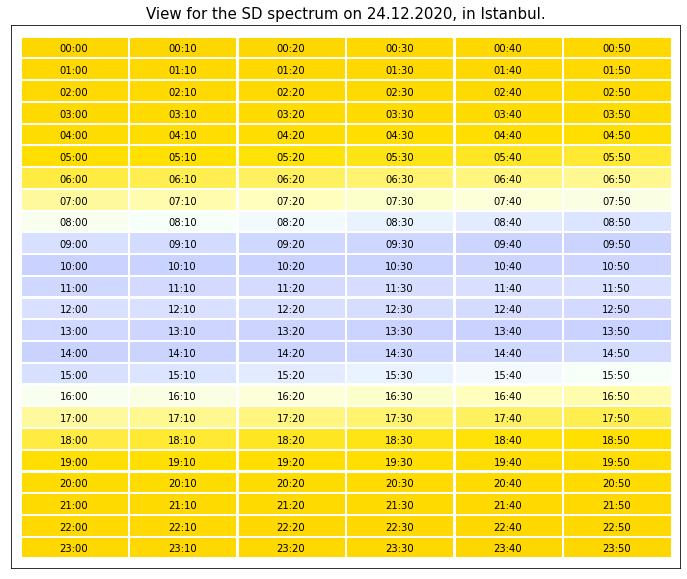

View for the SD spectrum on 24.12.2020.


In [7]:
### run the sky_view function

cs = cs_hdtv # choose color matching system (cs_hdtv, cs_smpte, cs_srgb)

day = datetime(2020,12,24)
lat = 41 # choose latitude from 'latitude_city' dictionary
alt = 25
tur = 2

Theta_v = 75 # (zenith=0, horizon=90)
Phi_v   = 0 # (east=-90, south=0, west=90, north=-180)


spectrum = ['SD','scotopic','photopic','total']
spec = spectrum[0] # choose the spectrum to be plotted

figure_size = (12,10)

sky_view(day,lat,alt,tur,Theta_v,Phi_v,spec,figure_size)

### Panoramic Sky View Function - Single Plot

In [8]:
def panoramic_sky_view(time, city, altitude, turbidity, theta_range_viewer, phi_range_viewer, spectrum, size, xlimit, ylimit):
    
    latitude = city_latitude[city]
    
    ### matrices and vectors from "Preetham et al. - A Practical Analytic Model for Daylight" (Appendix A.2)
    A1 = [[ 0.1787,-1.4630],
          [-0.3554, 0.4275],
          [-0.0227, 5.3251],
          [ 0.1206,-2.5771],
          [-0.0670, 0.3703]]
    
    A2 = [[-0.0193,-0.2592],
          [-0.0665, 0.0008],
          [-0.0004, 0.2125],
          [-0.0641,-0.8989],
          [-0.0033, 0.0452]]
    
    A3 = [[-0.0167,-0.2608],
          [-0.0950, 0.0092],
          [-0.0079, 0.2102],
          [-0.0441,-1.6537],
          [-0.0109, 0.0529]]
    
    Y_coefficient = np.dot(A1, [turbidity,1]) # [Ay, By, Cy, Dy, Ey]
    x_coefficient = np.dot(A2, [turbidity,1]) # [xy, xy, xy, xy, xy]
    y_coefficient = np.dot(A3, [turbidity,1]) # [yy, yy, yy, yy, yy]
    
    xz_matrix = [[ 0.0017,-0.0037, 0.0021, 0.0000],
                 [-0.0290, 0.0638,-0.0320, 0.0039],
                 [ 0.1169,-0.2120, 0.0605, 0.2589]]
    
    yz_matrix = [[ 0.0028,-0.0061, 0.0032, 0.0000],
                 [-0.0421, 0.0897,-0.0415, 0.0052],
                 [ 0.1535,-0.2676, 0.0667, 0.2669]]
    
    T_vector = [turbidity**2,turbidity,1]
    
    vision = []
    vision_sc = []
    vision_pc = []
    
    theta_difference = abs(theta_range_viewer[1]-theta_range_viewer[0])
    phi_difference = abs(phi_range_viewer[1]-phi_range_viewer[0])

    tt = theta_range_viewer[0]
    angle = []
    for i in range(theta_difference+1):
        pp = phi_range_viewer[0]
        for j in range(phi_difference+1):
            angle.append((tt,pp))
            pp += 1
        tt += 1
    
    n = (theta_difference+1)*(phi_difference+1)
    
    fig, ax = plt.subplots(figsize=size)
    for i in range(n):
        
        theta_v = angle[i][0]*(pi/180)
        phi_v = angle[i][1]*(pi/180)
        
        theta_s = sp.theta_z(time,latitude)
        phi_s = sp.solar_azimuth(time,latitude)
        
        gamma = arccos(cos(theta_v)*cos(theta_s) + sin(theta_v)*cos(phi_v)*sin(theta_s)*cos(phi_s) + sin(theta_v)*sin(phi_v)*sin(theta_s)*sin(phi_s))
        
        Chi = (4/9 - turbidity/120)*(pi - 2*theta_s)
        Yz = (4.0453*turbidity - 4.9710)*tan(Chi) - 0.2155*turbidity + 2.4192
        
        theta_s_vector = [theta_s**3,theta_s**2,theta_s,1]
        
        xz = np.dot(T_vector,xz_matrix)
        xz = np.dot(xz, theta_s_vector)
        
        yz = np.dot(T_vector,yz_matrix)
        yz = np.dot(yz, theta_s_vector)
        
        
        FY_theta_gamma = (1+Y_coefficient[0]*exp(Y_coefficient[1]/cos(theta_v))) * (1+Y_coefficient[2]*exp(Y_coefficient[3]*gamma) + Y_coefficient[4]*(cos(gamma))**2)
        FY_0_theta_s = (1+Y_coefficient[0]*exp(Y_coefficient[1])) * (1+Y_coefficient[2]*exp(Y_coefficient[3]*theta_s) + Y_coefficient[4]*(cos(theta_s))**2)
        
        Fx_theta_gamma = (1+x_coefficient[0]*exp(x_coefficient[1]/cos(theta_v))) * (1+x_coefficient[2]*exp(x_coefficient[3]*gamma) + x_coefficient[4]*(cos(gamma))**2)
        Fx_0_theta_s = (1+x_coefficient[0]*exp(x_coefficient[1])) * (1+x_coefficient[2]*exp(x_coefficient[3]*theta_s) + x_coefficient[4]*(cos(theta_s))**2)
        
        Fy_theta_gamma = (1+y_coefficient[0]*exp(y_coefficient[1]/cos(theta_v))) * (1+y_coefficient[2]*exp(y_coefficient[3]*gamma) + y_coefficient[4]*(cos(gamma))**2)
        Fy_0_theta_s = (1+y_coefficient[0]*exp(y_coefficient[1])) * (1+y_coefficient[2]*exp(y_coefficient[3]*theta_s)+ y_coefficient[4]*(cos(theta_s))**2)
        
        
        Y = Yz*(FY_theta_gamma/FY_0_theta_s)
        x = xz*(Fx_theta_gamma/Fx_0_theta_s)
        y = yz*(Fy_theta_gamma/Fy_0_theta_s)
        
        M1 = (-1.3515-1.7703*x+5.9114*y)/(0.0241+0.2562*x-0.7341*y)
        M2 = (0.0300-31.4424*x+30.0717*y)/(0.0241+0.2562*x-0.7341*y)
        
        SD = np.array(S0) + M1*np.array(S1) + M2*np.array(S2)
        
        #for i in range(len(SD)):
        #    if SD[i] < 0:
        #        SD[i] = S0[i]
        #    else: pass
        
        scotopic_vision = SD*scotopic_V
        photopic_vision = SD*photopic_V
        
        # plot the desired spectrum
        if   spectrum == 'SD'      : html_rgb = cs.spec_to_rgb(SD, out_fmt='html')
        elif spectrum == 'scotopic': html_rgb = cs.spec_to_rgb(scotopic_vision, out_fmt='html')
        elif spectrum == 'photopic': html_rgb = cs.spec_to_rgb(photopic_vision, out_fmt='html')
        elif spectrum == 'total'   : html_rgb = cs.spec_to_rgb(scotopic_vision+photopic_vision, out_fmt='html')
        else: print("Choose the spectrum!")
                
        x_coordinate, y_coordinate = i%(phi_difference+1), -(i//(phi_difference+1))
        patch = Rectangle(xy=(x_coordinate,y_coordinate), width=1, height=1, fc=html_rgb)
        ax.add_patch(patch)
        
    ax.set_aspect("equal")
    ax.set_xlim(xlimit)
    ax.set_ylim(ylimit)
    ax.set_xticks([])
    ax.set_yticks([])
    ax.set_facecolor('white')
    
    plt.title("Panoramic view of the sky in range \u03B8="+str(theta_range_viewer)+",\n\u03C6="+str(phi_range_viewer)+", on "+str(time)+", in "+city+".", fontsize=16)  #+"."+str(time.month)+"."+str(time.year)+", in "+city[latitude]+"."     
    
    plt.show()
    #fig.savefig(r"/Users/canartun/OneDrive/RESEARCH/SUNDOWNING SYNDROME/Results/Sky_View/PanoramicSkyView_"+city+"_Hour"+str(time.hour)+"Min"+str(time.minute)+".png", format='png', bbox_inches='tight')

    return False

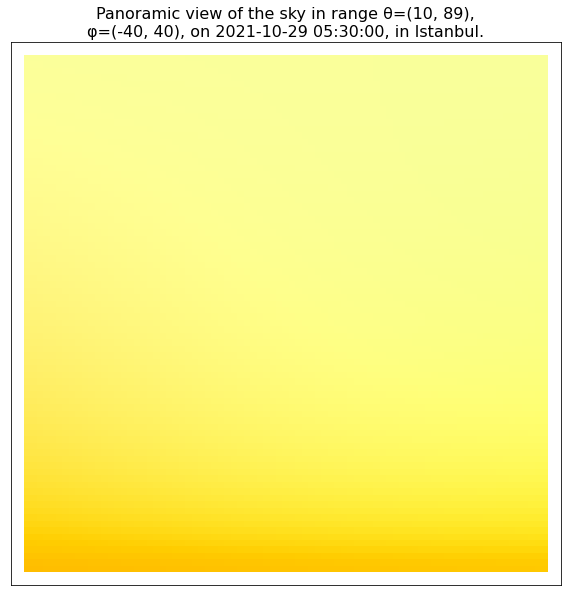

False

In [13]:
### run - panoramic_sky_view function (single plot)

cs = cs_hdtv # choose color matching system (cs_hdtv, cs_smpte, cs_srgb)

time = datetime(2021,10,29, 5,30)
city = "Istanbul" # choose city from 'city_latitude' dictionary
alt = 25
tur = 2

Theta_v_range = (10,89)   # (zenith=0, horizon=90)
Phi_v_range   = (-40,40) # (east=-90, south=0, west=90, north=-180)

spectrum = ['SD','scotopic','photopic','total']
spec = spectrum[0] # choose the spectrum to be plotted

figure_size = (12,10)
xaxis_limit, yaxis_limit = (-2,83), (-81,3)

panoramic_sky_view(time,city,alt,tur,Theta_v_range,Phi_v_range,spec,figure_size,xaxis_limit,yaxis_limit)

### Panoramic Sky View Function - Pano with 4 Plot

In [12]:
def panoramic_sky_view_PANO(day, hours, city, altitude, turbidity, theta_range_viewer, phi_range_viewer, size, xlimit, ylimit):
    
    latitude = city_latitude[city]
    
    ### matrices and vectors from "Preetham et al. - A Practical Analytic Model for Daylight" (Appendix A.2)
    A1 = [[ 0.1787,-1.4630],
          [-0.3554, 0.4275],
          [-0.0227, 5.3251],
          [ 0.1206,-2.5771],
          [-0.0670, 0.3703]]
    
    A2 = [[-0.0193,-0.2592],
          [-0.0665, 0.0008],
          [-0.0004, 0.2125],
          [-0.0641,-0.8989],
          [-0.0033, 0.0452]]
    
    A3 = [[-0.0167,-0.2608],
          [-0.0950, 0.0092],
          [-0.0079, 0.2102],
          [-0.0441,-1.6537],
          [-0.0109, 0.0529]]
    
    Y_coefficient = np.dot(A1, [turbidity,1]) # [Ay, By, Cy, Dy, Ey]
    x_coefficient = np.dot(A2, [turbidity,1]) # [xy, xy, xy, xy, xy]
    y_coefficient = np.dot(A3, [turbidity,1]) # [yy, yy, yy, yy, yy]
    
    xz_matrix = [[ 0.0017,-0.0037, 0.0021, 0.0000],
                 [-0.0290, 0.0638,-0.0320, 0.0039],
                 [ 0.1169,-0.2120, 0.0605, 0.2589]]
    
    yz_matrix = [[ 0.0028,-0.0061, 0.0032, 0.0000],
                 [-0.0421, 0.0897,-0.0415, 0.0052],
                 [ 0.1535,-0.2676, 0.0667, 0.2669]]
    
    T_vector = [turbidity**2,turbidity,1]
    
    vision = []
    vision_sc = []
    vision_pc = []
    
    theta_difference = abs(theta_range_viewer[1]-theta_range_viewer[0])
    phi_difference = abs(phi_range_viewer[1]-phi_range_viewer[0])

    tt = theta_range_viewer[0]
    angle = []
    for i in range(theta_difference+1):
        pp = phi_range_viewer[0]
        for j in range(phi_difference+1):
            angle.append((tt,pp))
            pp += 1
        tt += 1
    
    n = (theta_difference+1)*(phi_difference+1)
    
    ax = []
    fig = plt.figure(figsize=size, dpi=100)
    fig.text(0.5, 0.9, "Panoramic view of the sky in range\n\u03B8="+str(theta_range_viewer)+", \u03C6="+str(phi_range_viewer)+", on "+str(day.day)+"."+str(day.month)+"."+str(day.year)+", in "+city+".", ha='center', fontsize=16)
    
    for j in range(4):
        
        time = day + hours[j]
        
        ax = plt.subplot(2,2,j+1)
        for i in range(n):
            
            theta_v = angle[i][0]*(pi/180)
            phi_v = angle[i][1]*(pi/180)
            
            theta_s = sp.theta_z(time,latitude)
            phi_s = sp.solar_azimuth(time,latitude)
            
            gamma = arccos(cos(theta_v)*cos(theta_s) + sin(theta_v)*cos(phi_v)*sin(theta_s)*cos(phi_s) + sin(theta_v)*sin(phi_v)*sin(theta_s)*sin(phi_s))
            
            Chi = (4/9 - turbidity/120)*(pi - 2*theta_s)
            Yz = (4.0453*turbidity - 4.9710)*tan(Chi) - 0.2155*turbidity + 2.4192
            
            theta_s_vector = [theta_s**3,theta_s**2,theta_s,1]
            
            xz = np.dot(T_vector,xz_matrix)
            xz = np.dot(xz, theta_s_vector)
            
            yz = np.dot(T_vector,yz_matrix)
            yz = np.dot(yz, theta_s_vector)
            
            FY_theta_gamma = (1+Y_coefficient[0]*exp(Y_coefficient[1]/cos(theta_v))) * (1+Y_coefficient[2]*exp(Y_coefficient[3]*gamma) + Y_coefficient[4]*(cos(gamma))**2)
            FY_0_theta_s = (1+Y_coefficient[0]*exp(Y_coefficient[1])) * (1+Y_coefficient[2]*exp(Y_coefficient[3]*theta_s) + Y_coefficient[4]*(cos(theta_s))**2)
            
            Fx_theta_gamma = (1+x_coefficient[0]*exp(x_coefficient[1]/cos(theta_v))) * (1+x_coefficient[2]*exp(x_coefficient[3]*gamma) + x_coefficient[4]*(cos(gamma))**2)
            Fx_0_theta_s = (1+x_coefficient[0]*exp(x_coefficient[1])) * (1+x_coefficient[2]*exp(x_coefficient[3]*theta_s) + x_coefficient[4]*(cos(theta_s))**2)
            
            Fy_theta_gamma = (1+y_coefficient[0]*exp(y_coefficient[1]/cos(theta_v))) * (1+y_coefficient[2]*exp(y_coefficient[3]*gamma) + y_coefficient[4]*(cos(gamma))**2)
            Fy_0_theta_s = (1+y_coefficient[0]*exp(y_coefficient[1])) * (1+y_coefficient[2]*exp(y_coefficient[3]*theta_s)+ y_coefficient[4]*(cos(theta_s))**2)
            
            Y = Yz*(FY_theta_gamma/FY_0_theta_s)
            x = xz*(Fx_theta_gamma/Fx_0_theta_s)
            y = yz*(Fy_theta_gamma/Fy_0_theta_s)
            
            M1 = (-1.3515-1.7703*x+5.9114*y)/(0.0241+0.2562*x-0.7341*y)
            M2 = (0.0300-31.4424*x+30.0717*y)/(0.0241+0.2562*x-0.7341*y)
            
            SD = np.array(S0) + M1*np.array(S1) + M2*np.array(S2)
            
            html_rgb = cs.spec_to_rgb(SD, out_fmt='html')
            
            x_coordinate, y_coordinate = i%(phi_difference+1), -(i//(phi_difference+1))
            patch = Rectangle(xy=(x_coordinate,y_coordinate), width=1, height=1, fc=html_rgb)
            ax.add_patch(patch)
            
            ax.set_aspect("equal")
            ax.set_xlim(xlimit)
            ax.set_ylim(ylimit)
            ax.set_xticks([])
            ax.set_yticks([])
            ax.set_facecolor('white')
            
            seconds = hours[j].seconds//60 # H:M formatter
            minutes = seconds//60
            seconds %= 60
            ax.text(2,-3, "Hour: %02i:%02i"%(minutes,seconds))
    
    plt.subplots_adjust(wspace=0, hspace=0)
    plt.show()
    #fig.savefig(r"/Users/canartun/OneDrive/RESEARCH/SUNDOWNING SYNDROME/Results/Sky_View/PanoramicSkyViewPANO_"+city+"_Day"+str(time.day)+"."+str(time.month)+"."+str(time.year)+".png", format='png', bbox_inches='tight')

    return False

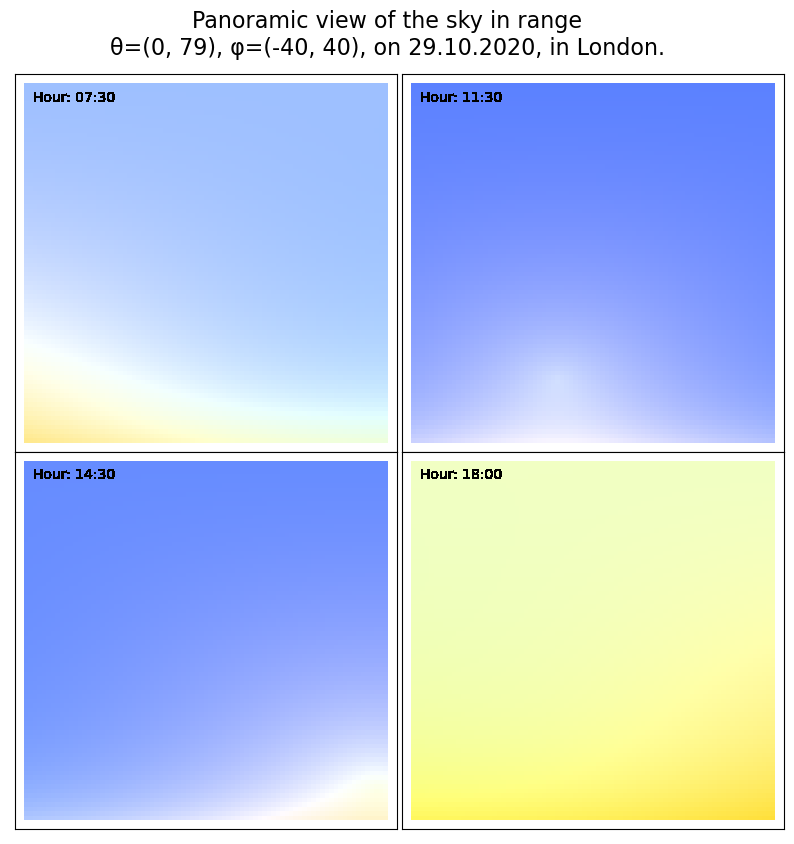

False

In [13]:
### run - panoramic_sky_view_PANO (pano with 4 plot)

cs = cs_hdtv # choose color matching system (cs_hdtv, cs_smpte, cs_srgb)


day   = datetime(2020,10,29)

hours = [timedelta(minutes=60* 7 +30), # arrange 4 hours to be plotted
         timedelta(minutes=60* 11+30),
         timedelta(minutes=60* 14+30),
         timedelta(minutes=60* 18+0)]

city = "London" # choose city from 'city_latitude' dictionary

alt = 25
tur = 2

Theta_v_range = (0,79)   # (zenith=0, horizon=90)
Phi_v_range   = (-40,40) # (east=-90, south=0, west=90, north=-180)

figure_size = (10,10)
xaxis_limit, yaxis_limit = (-2,83), (-81,3)

panoramic_sky_view_PANO(day,hours,city,alt,tur,Theta_v_range,Phi_v_range,figure_size,xaxis_limit,yaxis_limit)

In [12]:
### test for completeness of the sky view plot by the viewing range

# choose range and run the cell for test
Theta_v_range = (10,89)
Phi_v_range   = (0,80)


theta_difference = abs(Theta_v_range[1]-Theta_v_range[0])
phi_difference = abs(Phi_v_range[1]-Phi_v_range[0])

print("0 means the plot will be perfect square, otherwise last line will be incomplete: ", (theta_difference+1)*(phi_difference+1)%phi_difference)

0 means the plot will be perfect square, otherwise last line will be incomplete:  0


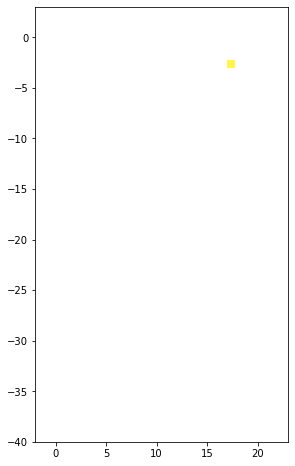

In [78]:
time = datetime(2021,10,29, 5,30)

cs = cs_hdtv
altitude = 25
turbidity = 1
theta_range_viewer = (40,79)
phi_range_viewer = (-10,10)
spectrum = 'SD'
latitude = 41
    
    ### matrices and vectors from "Preetham et al. - A Practical Analytic Model for Daylight" (Appendix A.2)
A1 = [[ 0.1787,-1.4630],
          [-0.3554, 0.4275],
          [-0.0227, 5.3251],
          [ 0.1206,-2.5771],
          [-0.0670, 0.3703]]
    
A2 = [[-0.0193,-0.2592],
          [-0.0665, 0.0008],
          [-0.0004, 0.2125],
          [-0.0641,-0.8989],
          [-0.0033, 0.0452]]
    
A3 = [[-0.0167,-0.2608],
          [-0.0950, 0.0092],
          [-0.0079, 0.2102],
          [-0.0441,-1.6537],
          [-0.0109, 0.0529]]
    
Y_coefficient = np.dot(A1, [turbidity,1]) # [Ay, By, Cy, Dy, Ey]
x_coefficient = np.dot(A2, [turbidity,1]) # [xy, xy, xy, xy, xy]
y_coefficient = np.dot(A3, [turbidity,1]) # [yy, yy, yy, yy, yy]
    
xz_matrix = [[ 0.0017,-0.0037, 0.0021, 0.0000],
                 [-0.0290, 0.0638,-0.0320, 0.0039],
                 [ 0.1169,-0.2120, 0.0605, 0.2589]]
    
yz_matrix = [[ 0.0028,-0.0061, 0.0032, 0.0000],
                 [-0.0421, 0.0897,-0.0415, 0.0052],
                 [ 0.1535,-0.2676, 0.0667, 0.2669]]
    
T_vector = [turbidity**2,turbidity,1]
    
vision = []
vision_sc = []
vision_pc = []
    
theta_difference = abs(theta_range_viewer[1]-theta_range_viewer[0])
phi_difference = abs(phi_range_viewer[1]-phi_range_viewer[0])

tt = theta_range_viewer[0]
angle = []
for i in range(theta_difference+1):
    pp = phi_range_viewer[0]
    for j in range(phi_difference+1):
        angle.append((tt,pp))
        pp += 1
    tt += 1
    
n = (theta_difference+1)*(phi_difference+1)
    
fig, ax = plt.subplots(figsize=(8,8))
for i in range(n):
        
    theta_v = angle[i][0]*(pi/180)
    phi_v = angle[i][1]*(pi/180)
        
    theta_s = sp.theta_z(time,latitude)
    phi_s = sp.solar_azimuth(time,latitude)
        
    gamma = arccos(cos(theta_v)*cos(theta_s) + sin(theta_v)*cos(phi_v)*sin(theta_s)*cos(phi_s) + sin(theta_v)*sin(phi_v)*sin(theta_s)*sin(phi_s))
        
    Chi = (4/9 - turbidity/120)*(pi - 2*theta_s)
    Yz = (4.0453*turbidity - 4.9710)*tan(Chi) - 0.2155*turbidity + 2.4192
        
    theta_s_vector = [theta_s**3,theta_s**2,theta_s,1]
        
    xz = np.dot(T_vector,xz_matrix)
    xz = np.dot(xz, theta_s_vector)
        
    yz = np.dot(T_vector,yz_matrix)
    yz = np.dot(yz, theta_s_vector)
        
        
    FY_theta_gamma = (1+Y_coefficient[0]*exp(Y_coefficient[1]/cos(theta_v))) * (1+Y_coefficient[2]*exp(Y_coefficient[3]*gamma) + Y_coefficient[4]*(cos(gamma))**2)
    FY_0_theta_s = (1+Y_coefficient[0]*exp(Y_coefficient[1])) * (1+Y_coefficient[2]*exp(Y_coefficient[3]*theta_s) + Y_coefficient[4]*(cos(theta_s))**2)
        
    Fx_theta_gamma = (1+x_coefficient[0]*exp(x_coefficient[1]/cos(theta_v))) * (1+x_coefficient[2]*exp(x_coefficient[3]*gamma) + x_coefficient[4]*(cos(gamma))**2)
    Fx_0_theta_s = (1+x_coefficient[0]*exp(x_coefficient[1])) * (1+x_coefficient[2]*exp(x_coefficient[3]*theta_s) + x_coefficient[4]*(cos(theta_s))**2)
        
    Fy_theta_gamma = (1+y_coefficient[0]*exp(y_coefficient[1]/cos(theta_v))) * (1+y_coefficient[2]*exp(y_coefficient[3]*gamma) + y_coefficient[4]*(cos(gamma))**2)
    Fy_0_theta_s = (1+y_coefficient[0]*exp(y_coefficient[1])) * (1+y_coefficient[2]*exp(y_coefficient[3]*theta_s)+ y_coefficient[4]*(cos(theta_s))**2)
        
        
    Y = Yz*(FY_theta_gamma/FY_0_theta_s)
    x = xz*(Fx_theta_gamma/Fx_0_theta_s)
    y = yz*(Fy_theta_gamma/Fy_0_theta_s)
        
    M1 = (-1.3515-1.7703*x+5.9114*y)/(0.0241+0.2562*x-0.7341*y)
    M2 = (0.0300-31.4424*x+30.0717*y)/(0.0241+0.2562*x-0.7341*y)
        
    SD = np.array(S0) + M1*np.array(S1) + M2*np.array(S2)
    
    for i in range(len(SD)):
        if SD[i] < 0:
            SD[i] = 1
        else: pass
    
        
    html_rgb = cs.spec_to_rgb(SD, out_fmt='html')
                 
    x_coordinate, y_coordinate = i%(phi_difference+1), -(i//(phi_difference+1))
    patch = Rectangle(xy=(x_coordinate,y_coordinate), width=0.71, height=0.71, fc=html_rgb)
    ax.add_patch(patch)
        
ax.set_aspect("equal")
ax.set_xlim((-2,23))
ax.set_ylim((-40,3))
ax.set_facecolor('white')
    
plt.show()

In [82]:
time = datetime(2021,10,29, 6,30)

altitude = 25
turbidity = 1
theta_range_viewer = (40,79)
phi_range_viewer = (-10,10)
latitude = 41

A1 = [[ 0.1787,-1.4630],[-0.3554, 0.4275],[-0.0227, 5.3251],[ 0.1206,-2.5771],[-0.0670, 0.3703]]    
A2 = [[-0.0193,-0.2592],[-0.0665, 0.0008],[-0.0004, 0.2125],[-0.0641,-0.8989],[-0.0033, 0.0452]]
A3 = [[-0.0167,-0.2608],[-0.0950, 0.0092],[-0.0079, 0.2102],[-0.0441,-1.6537],[-0.0109, 0.0529]]
Y_coefficient,x_coefficient,y_coefficient = np.dot(A1, [turbidity,1]),np.dot(A2, [turbidity,1]),np.dot(A3, [turbidity,1])
xz_matrix = [[ 0.0017,-0.0037, 0.0021, 0.0000],[-0.0290, 0.0638,-0.0320, 0.0039],[ 0.1169,-0.2120, 0.0605, 0.2589]]
yz_matrix = [[ 0.0028,-0.0061, 0.0032, 0.0000],[-0.0421, 0.0897,-0.0415, 0.0052],[ 0.1535,-0.2676, 0.0667, 0.2669]]
theta_v, phi_v = angle[i][0]*(pi/180), angle[i][1]*(pi/180)
theta_s, phi_s = sp.theta_z(time,latitude), sp.solar_azimuth(time,latitude)
gamma = arccos(cos(theta_v)*cos(theta_s) + sin(theta_v)*cos(phi_v)*sin(theta_s)*cos(phi_s) + sin(theta_v)*sin(phi_v)*sin(theta_s)*sin(phi_s))   
Chi = (4/9 - turbidity/120)*(pi - 2*theta_s)
Yz = (4.0453*turbidity - 4.9710)*tan(Chi) - 0.2155*turbidity + 2.4192    
xz = np.dot([turbidity**2,turbidity,1],xz_matrix)
xz = np.dot(xz, [theta_s**3,theta_s**2,theta_s,1])
yz = np.dot([turbidity**2,turbidity,1],yz_matrix)
yz = np.dot(yz, [theta_s**3,theta_s**2,theta_s,1])
FY_theta_gamma = (1+Y_coefficient[0]*exp(Y_coefficient[1]/cos(theta_v))) * (1+Y_coefficient[2]*exp(Y_coefficient[3]*gamma) + Y_coefficient[4]*(cos(gamma))**2)
FY_0_theta_s = (1+Y_coefficient[0]*exp(Y_coefficient[1])) * (1+Y_coefficient[2]*exp(Y_coefficient[3]*theta_s) + Y_coefficient[4]*(cos(theta_s))**2)
Fx_theta_gamma = (1+x_coefficient[0]*exp(x_coefficient[1]/cos(theta_v))) * (1+x_coefficient[2]*exp(x_coefficient[3]*gamma) + x_coefficient[4]*(cos(gamma))**2)
Fx_0_theta_s = (1+x_coefficient[0]*exp(x_coefficient[1])) * (1+x_coefficient[2]*exp(x_coefficient[3]*theta_s) + x_coefficient[4]*(cos(theta_s))**2)
Fy_theta_gamma = (1+y_coefficient[0]*exp(y_coefficient[1]/cos(theta_v))) * (1+y_coefficient[2]*exp(y_coefficient[3]*gamma) + y_coefficient[4]*(cos(gamma))**2)
Fy_0_theta_s = (1+y_coefficient[0]*exp(y_coefficient[1])) * (1+y_coefficient[2]*exp(y_coefficient[3]*theta_s)+ y_coefficient[4]*(cos(theta_s))**2)
Y, x, y = Yz*(FY_theta_gamma/FY_0_theta_s), xz*(Fx_theta_gamma/Fx_0_theta_s), yz*(Fy_theta_gamma/Fy_0_theta_s)
M1 = (-1.3515-1.7703*x+5.9114*y)/(0.0241+0.2562*x-0.7341*y)
M2 = (0.0300-31.4424*x+30.0717*y)/(0.0241+0.2562*x-0.7341*y)
        
SD = np.array(S0) + M1*np.array(S1) + M2*np.array(S2)
        
for i in range(len(SD)):
    if SD[i] < 0:
        SD[i] = S0[i]
    else: pass

SD

array([ 40.75285974,  45.33184467,  49.9108296 ,  66.48553056,
        83.06023151,  86.6318825 ,  90.20353349,  91.47939771,
        92.75526193,  90.15931666,  87.56337139,  98.33684048,
       109.11030958, 115.56122632, 122.01214306, 122.38330315,
       122.75446324, 121.16572227, 119.5769813 , 120.20425506,
       120.83152882, 116.43262135, 112.03371388, 112.05173788,
       112.06976188, 111.1348083 , 110.19985472, 108.69753033,
       107.19520595, 108.47313101, 109.75105607, 107.56291294,
       105.3747698 , 105.01784632, 104.66092284, 102.33046142,
       100.        ,  97.97110662,  95.94221325,  95.36175182,
        94.7812904 ,  89.31983668,  83.85838295,  83.26689175,
        82.67540055,  81.43477263,  80.19414471,  78.56503936,
        76.93593401,  74.27738901,  71.61884402,  69.9513301 ,
        68.28381617,  65.72592248,  63.16802879,  61.74461316,
        60.32119754,  59.97359267,  59.6259878 ,  57.14092728,
        54.65586676,  52.60005472,  50.54424268,  49.97

color: #ddf9ff


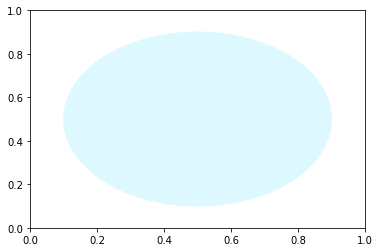

In [83]:
### color test for a given spectrum

spectrum = SD

cs = cs_hdtv
color = cs.spec_to_rgb(spectrum, out_fmt='html')
print("color:",color)

fig, ax = plt.subplots()
circle = plt.Circle((0.5, 0.5), 0.4, color=color)
ax.add_artist(circle);